WELFake Dataset- Exploratory Data Analysis



*  Label 0 = Fake News
*  Label 1 = Real News




In [ ]:
import pandas as pd
import matplotlib.pyplot as plot
import re
from collections import Counter

df = pd.read_csv("WELFake_Dataset.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print()
df.info()
df.head()


Shape: (72134, 4)
Columns: ['Unnamed: 0', 'title', 'text', 'label']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [ ]:
print(df["label"].value_counts())
print()
print((df["label"].value_counts(normalize=True) * 100).round(2))


label
1    37106
0    35028
Name: count, dtype: int64

label
1    51.44
0    48.56
Name: proportion, dtype: float64


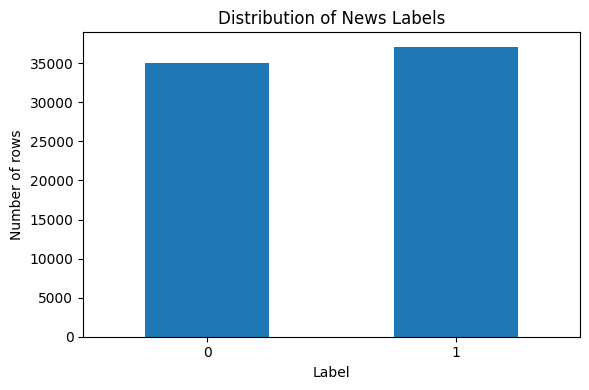

In [ ]:
df["label"].value_counts().sort_index().plot(kind="bar", figsize=(6, 4))
plot.xlabel("Label")
plot.ylabel("Number of rows")
plot.title("Distribution of News Labels")
plot.xticks(rotation=0)
plot.tight_layout()
plot.show()




First count missing values, then inspect a few examples. But didn't delete the mmissing values yet.

In [ ]:
print(df.isnull().sum())


Unnamed: 0      0
title         558
text           39
label           0
dtype: int64


In [ ]:
df[df["title"].isnull()][["title", "text", "label"]].head()


,title,text,label
1,NaN,Did they post their votes for Hillary already?,1
43,NaN,True. Hillary needs a distraction and what bet...,1
162,NaN,All eyes on Electoral delegates. The People kn...,1
185,NaN,Cool,1
269,NaN,A leading US senator: US Supporting War in Syr...,1


In [ ]:
df[df["text"].isnull()][["title", "text", "label"]].head()


,title,text,label
2457,Après le succès de « Mariés au premier regard ...,NaN,1
3534,Elections US : les premières estimations donne...,NaN,1
3709,110% des Américains assurent qu’ils continuero...,NaN,1
5612,Des millions d’Américains recherchent massivem...,NaN,1
6270,Vladimir Poutine est élu 45e Président des Eta...,NaN,1


In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated title occurrences:", df.duplicated(subset="title").sum())
print("Repeated text occurrences:", df.duplicated(subset="text").sum())
print("Repeated title-text pair occurrences:", df.duplicated(subset=["title", "text"]).sum())


Exact duplicate rows: 0
Repeated title occurrences: 9786
Repeated text occurrences: 9415
Repeated title-text pair occurrences: 8456


In [ ]:
duplicate_titles = df[df.duplicated(subset="title", keep=False)].sort_values("title")
duplicate_titles[["title", "text", "label"]].head(10)


,title,text,label
47584,McConnell Says He’ll Obstruct ANY Effort To H...,Siding with Trump s Attorney General Jeff Sess...,1
38487,McConnell Says He’ll Obstruct ANY Effort To H...,Siding with Trump s Attorney General Jeff Sess...,1
40330,"""Top Five Clinton Donors Are Jewish"" - How Ant...","""Top Five Clinton Donors Are Jewish"" - How Ant...",1
34585,"""Top Five Clinton Donors Are Jewish"" - How Ant...","""Top Five Clinton Donors Are Jewish"" - How Ant...",1
58423,"""Top Five Clinton Donors Are Jewish"" - How Ant...","""Top Five Clinton Donors Are Jewish"" - How Ant...",1
15085,#2816: Clinton Pride’s 8(a) Pig Farm Bridge – ...,United States Marine Field McConnell Plum Cit...,1
22321,#2816: Clinton Pride’s 8(a) Pig Farm Bridge – ...,United States Marine Field McConnell Plum Cit...,1
1946,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...,Hillary may find out she needs more than black...,1
22104,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...,Hillary may find out she needs more than black...,1
44689,#Austin: Fights Break Out Between Police and S...,Commies carrying flags fought with the Austin ...,1


In [ ]:
duplicate_texts = df[df.duplicated(subset="text", keep=False)].sort_values("text")
duplicate_texts[["title", "text", "label"]].head(10)


,title,text,label
28733,Hillary Is 70 Days Away From Controlling All F...,"\n\n \nIf Clinton is elected, Obama will hand ...",1
33501,Hillary Is 70 Days Away From Controlling All F...,"\n\n \nIf Clinton is elected, Obama will hand ...",1
16419,Just Another Day In the Life of the Clinton Cr...,"\n\n \nIn the past 24 hours, some very stunnin...",1
24633,Just Another Day In the Life of the Clinton Cr...,"\n\n \nIn the past 24 hours, some very stunnin...",1
12670,"14 Days to Do 14 Things, If You Want to Surviv...",\n\n \nUPDATE: HILLARY CLINTON IS AGAIN UNDER ...,1
1276,"14 Days to Do 14 Things, If Hillary’s Indicted...",\n\n \nUPDATE: HILLARY CLINTON IS AGAIN UNDER ...,1
20004,"14 Days to Do 14 Things, If Hillary’s Indicted...",\n\n \nUPDATE: HILLARY CLINTON IS AGAIN UNDER ...,1
24596,"CNN Fired Donna Brazile 2 Weeks Ago, Made It P...",\n\nCNN finally made it public that they have ...,1
28343,"CNN Fired Donna Brazile 2 Weeks Ago, Made It P...",\n\nCNN finally made it public that they have ...,1
23436,"Project Veritas Video 4 - 20K Bribery to DNC, ...",\n\nIn the effort to prove the credibility of ...,1


In [ ]:

pair_label_counts = df.groupby(["title", "text"], dropna=False)["label"].nunique()
print("Title-text groups with conflicting labels:", (pair_label_counts > 1).sum())


Title-text groups with conflicting labels: 0




Here, length means **number of words**, not number of characters. Missing values remain missing in these calculations.

In [ ]:
title_len = df["title"].str.split().str.len()
text_len = df["text"].str.split().str.len()

print("Headline word-count summary:")
print(title_len.describe())
print()
print("Article word-count summary:")
print(text_len.describe())


Headline word-count summary:
count    71576.000000
mean        12.268218
std          4.133661
min          1.000000
25%          9.000000
50%         12.000000
75%         14.000000
max         72.000000
Name: title, dtype: float64

Article word-count summary:
count    72095.000000
mean       540.843346
std        625.442464
min          0.000000
25%        227.000000
50%        399.000000
75%        667.000000
max      24234.000000
Name: text, dtype: float64


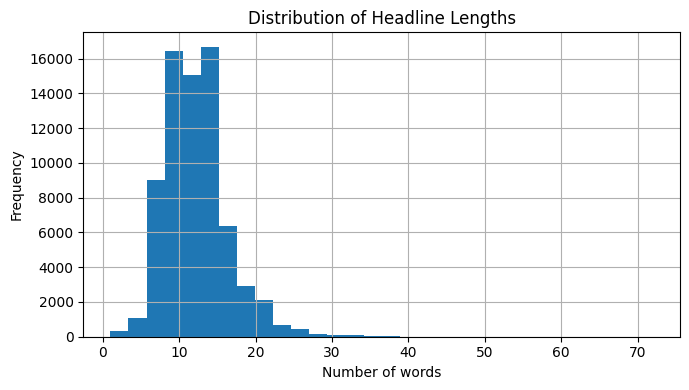

In [ ]:
title_len.hist(bins=30, figsize=(7, 4))
plot.xlabel("Number of words")
plot.ylabel("Frequency")
plot.title("Distribution of Headline Lengths")
plot.tight_layout()
plot.show()


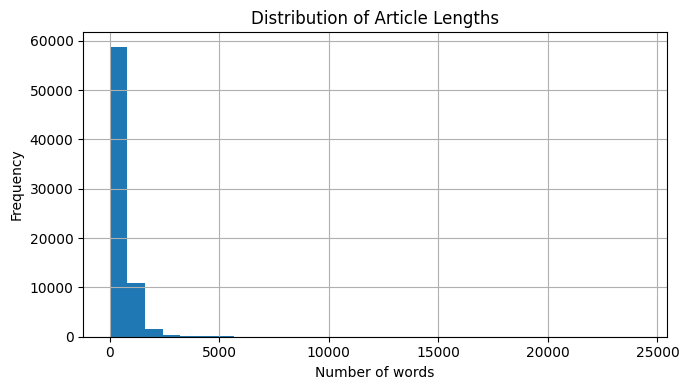

In [ ]:
text_len.hist(bins=30, figsize=(7, 4))
plot.xlabel("Number of words")
plot.ylabel("Frequency")
plot.title("Distribution of Article Lengths")
plot.tight_layout()
plot.show()




A difference in length can be an interesting pattern, but it does not prove that a story is fake or real.

In [ ]:
df["title_len"] = title_len
df["text_len"] = text_len

print(df.groupby("label")[["title_len", "text_len"]].median())


       title_len  text_len
label                     
0           11.0     427.0
1           13.0     369.0


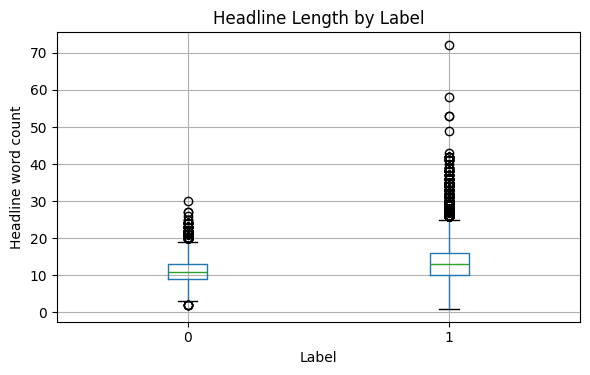

In [ ]:
df.boxplot(column="title_len", by="label", figsize=(6, 4))
plot.xlabel("Label")
plot.ylabel("Headline word count")
plot.title("Headline Length by Label")
plot.suptitle("")
plot.tight_layout()
plot.show()


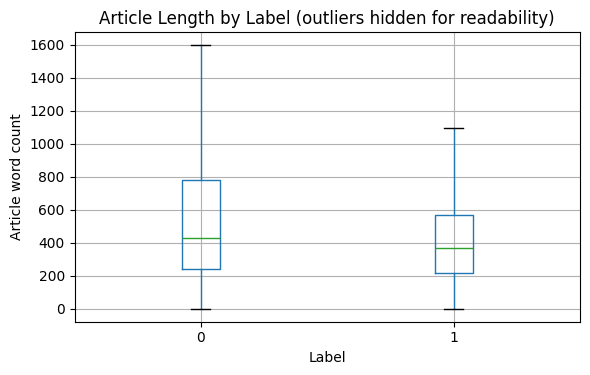

In [ ]:

df.boxplot(column="text_len", by="label", showfliers=False, figsize=(6, 4))
plot.xlabel("Label")
plot.ylabel("Article word count")
plot.title("Article Length by Label (outliers hidden for readability)")
plot.suptitle("")
plot.tight_layout()
plot.show()




This is a simple first look at frequent words. It lowercases text and removes punctuation, but does not claim that word frequency can establish whether an article is true. The two labels are shown separately.

In [ ]:
def common_words(text_series, number=15):
    words = []
    for article in text_series.dropna():
        article = article.lower()
        words.extend(re.findall(r"\b[a-z]{2,}\b", article))
    return Counter(words).most_common(number)

for label_value in sorted(df["label"].dropna().unique()):
    print("\nMost common words for label", label_value)
    print(common_words(df.loc[df["label"] == label_value, "text"], 15))



Most common words for label 0
[('the', 1185992), ('to', 573313), ('of', 514486), ('and', 465218), ('in', 430776), ('that', 259158), ('on', 216509), ('for', 193669), ('said', 184607), ('is', 158734), ('he', 154999), ('it', 142785), ('with', 133629), ('was', 132623), ('as', 122066)]

Most common words for label 1
[('the', 1056116), ('to', 532036), ('of', 477833), ('and', 449219), ('in', 333408), ('that', 272567), ('is', 220433), ('for', 171817), ('it', 155771), ('on', 147962), ('with', 118306), ('as', 115256), ('he', 114224), ('was', 112608), ('this', 109853)]


In [ ]:
title_empty = df["title"].fillna("").str.strip().eq("")
text_empty = df["text"].fillna("").str.strip().eq("")

print("Empty or missing titles:", title_empty.sum())
print("Empty or missing article texts:", text_empty.sum())
print("Articles with 5 or fewer words:", (df["text"].fillna("").str.split().str.len() <= 5).sum())

df.loc[text_empty | (df["text"].fillna("").str.split().str.len() <= 5),
       ["title", "text", "label"]].head(10)


Empty or missing titles: 558
Empty or missing article texts: 783
Articles with 5 or fewer words: 1030


,title,text,label
7,HOUSE INTEL CHAIR On Trump-Russia Fake Story: ...,,1
106,MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trum...,,1
185,NaN,Cool,1
325,Ohio State University Student Says Terrorist A...,,1
358,NaN,Obamas blunder.,1
364,JULIAN ASSANGE REVEALS John Podesta’s Hilariou...,,1
421,HEATED! TUCKER CARLSON Totally Shuts Down Radi...,https://www.youtube.com/watch?v=RRPSCqkAJgk,1
512,OBAMA’S LIST OF 21 MEDAL OF FREEDOM Recipients...,,1
514,HILARIOUS TRUMP CHRISTMAS VIDEO: “It’s The Mos...,,1
555,AWESOME! JEWISH DEMOCRAT LEADER Hits Back At H...,,1


In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)

df["clean_title"] = df["title"].fillna("").apply(clean_text)
df["clean_text"] = df["text"].fillna("").apply(clean_text)

df[["title", "clean_title", "label"]].head()


,title,clean_title,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,law enforcement high alert following threats c...,1
1,NaN,,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,unbelievable obama s attorney general says cha...,1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",bobby jindal raised hindu uses story christian...,0
4,SATAN 2: Russia unvelis an image of its terrif...,satan russia unvelis image terrifying new supe...,1


In [ ]:
from collections import Counter

def get_top_words(series, number=15):
    words = " ".join(series.dropna()).split()
    return Counter(words).most_common(number)

for label_value in sorted(df["label"].dropna().unique()):
    print("\\nTop words in headlines for label", label_value)
    print(get_top_words(df.loc[df["label"] == label_value, "clean_title"], 15))
    print("\\nTop words in article text for label", label_value)
    print(get_top_words(df.loc[df["label"] == label_value, "clean_text"], 15))


\nTop words in headlines for label 0
[('s', 11731), ('trump', 8513), ('new', 7704), ('york', 6481), ('times', 6366), ('u', 5241), ('says', 3352), ('breitbart', 2402), ('house', 1794), ('clinton', 1357), ('obama', 1256), ('russia', 1184), ('white', 1088), ('north', 1037), ('state', 983)]
\nTop words in article text for label 0
[('s', 296264), ('said', 184607), ('trump', 107204), ('mr', 66091), ('u', 53541), ('president', 51302), ('new', 42528), ('people', 41792), ('t', 39540), ('state', 38872), ('states', 31669), ('government', 30110), ('reuters', 29333), ('house', 28578), ('clinton', 28570)]
\nTop words in headlines for label 1
[('trump', 11283), ('s', 10298), ('video', 8966), ('hillary', 3787), ('obama', 2951), ('clinton', 2403), ('t', 2208), ('watch', 2079), ('just', 1723), ('new', 1477), ('president', 1368), ('news', 1334), ('donald', 1212), ('breaking', 1137), ('america', 1134)]
\nTop words in article text for label 1
[('s', 233721), ('trump', 106967), ('t', 69077), ('said', 49709)

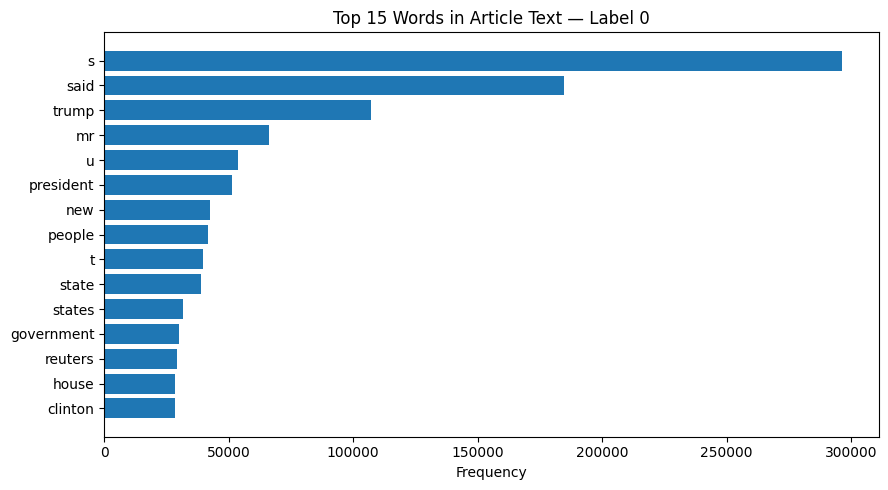

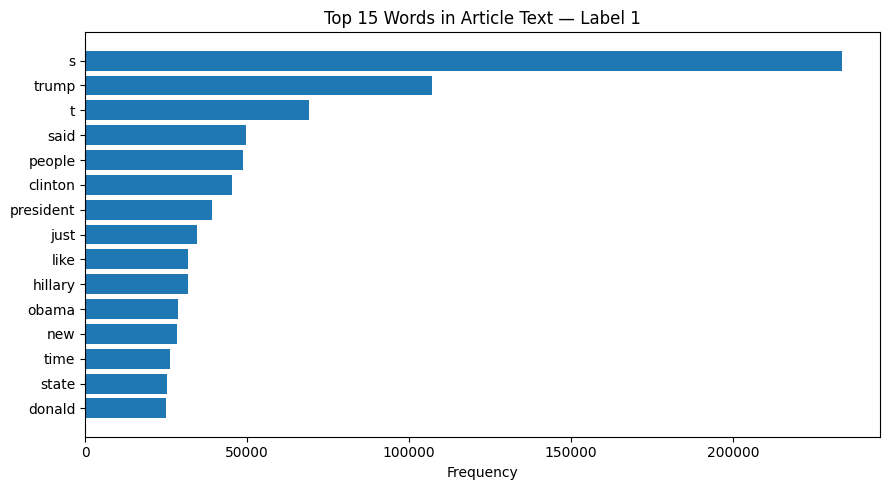

In [ ]:

for label_value in sorted(df["label"].dropna().unique()):
    top_words = get_top_words(df.loc[df["label"] == label_value, "clean_text"], 15)
    word_names = [item[0] for item in top_words]
    word_counts = [item[1] for item in top_words]

    plot.figure(figsize=(9, 5))
    plot.barh(word_names[::-1], word_counts[::-1])
    plot.xlabel("Frequency")
    plot.title("Top 15 Words in Article Text — Label " + str(label_value))
    plot.tight_layout()
    plot.show()


Machine Learning



Exploring the data set's size , column name and  first five rows.

In [ ]:
print(df.shape)
print(df.columns)
df.head()

(72134, 8)
Index(['Unnamed: 0', 'title', 'text', 'label', 'title_len', 'text_len',
       'clean_title', 'clean_text'],
      dtype='object')


,Unnamed: 0,title,text,label,title_len,text_len,clean_title,clean_text
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1,18.0,871.0,law enforcement high alert following threats c...,comment expected barack obama members fyf fuky...
1,1,NaN,Did they post their votes for Hillary already?,1,NaN,8.0,,did post votes hillary
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1,18.0,34.0,unbelievable obama s attorney general says cha...,demonstrators gathered night exercising consti...
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0,16.0,1321.0,bobby jindal raised hindu uses story christian...,dozen politically active pastors came private ...
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1,16.0,329.0,satan russia unvelis image terrifying new supe...,rs sarmat missile dubbed satan replace ss flie...


I cleaned the news text and prepared it for machine learning.

In [ ]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return " ".join(words)


if 'clean_text' not in df.columns:
    print("Generating 'clean_text' column...")
    df['clean_text'] = df['text'].fillna('').apply(clean_text)

X = df['clean_text'].fillna('')
y = df['label']

print("Text examples:")
print(X.head())

print("\nLabels:")
print(y.value_counts())

Text examples:
0    comment expected barack obama members fyf fuky...
1                               did post votes hillary
2    demonstrators gathered night exercising consti...
3    dozen politically active pastors came private ...
4    rs sarmat missile dubbed satan replace ss flie...
Name: clean_text, dtype: object

Labels:
label
1    37106
0    35028
Name: count, dtype: int64


I divided the dataset into training and testing sets. I used a 70:30 split.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 50493
Testing rows: 21641


 I used TF-IDF(Term Frequency–Inverse Document Frequency) to represent the text numerically, allowing the model to identify useful textual patterns.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (50493, 20000)
Testing matrix: (21641, 20000)


TRAINING THE MACHINE LEARNING MODELS

I used Logistic Regression as one of the baseline models for fake-news classification.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        stop_words="english",
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])


lr_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


I trained a Multinomial Naive Bayes classifier to explore a probability-based approach to news-text classification.

In [ ]:
from sklearn.naive_bayes import MultinomialNB


nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        stop_words="english",
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB(
        alpha=1.0
    ))
])


nb_pipeline.fit(X_train, y_train)

print("Naive Bayes training completed.")

Naive Bayes training completed.


I trained Linear Support Vector Machine (Linear SVM) to find a decision boundary that separates the two news categories in the TF-IDF feature space.

In [ ]:
from sklearn.svm import LinearSVC


svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        stop_words="english",
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        random_state=42
    ))
])


svm_pipeline.fit(X_train, y_train)

print("Linear SVM training completed.")

Linear SVM training completed.


EVALUATION FUNCTION

I created a reusable evaluation function to measure their performance consistently. This function calculates accuracy, macro precision, macro recall, and macro F1-score for each of the models.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(model, X_test, y_test, model_name):
    """
    Evaluate an already-trained model.
    Returns predictions and a dictionary of evaluation metrics.
    """


    y_pred = model.predict(X_test)


    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    }

    print(f"\n{'=' * 60}")
    print(f"Evaluation: {model_name}")
    print("=" * 60)

    print(f"Accuracy:       {metrics['Accuracy']:.4f}")
    print(f"Macro Precision:{metrics['Precision (Macro)']:.4f}")
    print(f"Macro Recall:   {metrics['Recall (Macro)']:.4f}")
    print(f"Macro F1:       {metrics['Macro F1']:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Fake News", "Real News"],
        zero_division=0
    ))

    return y_pred, metrics

COMPARING THE MODELS

 I evaluated the three trained models side by side and organized their results into a comparison table.


Evaluation: Logistic Regression
Accuracy:       0.9507
Macro Precision:0.9511
Macro Recall:   0.9504
Macro F1:       0.9507

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.96      0.94      0.95     10509
   Real News       0.94      0.96      0.95     11132

    accuracy                           0.95     21641
   macro avg       0.95      0.95      0.95     21641
weighted avg       0.95      0.95      0.95     21641



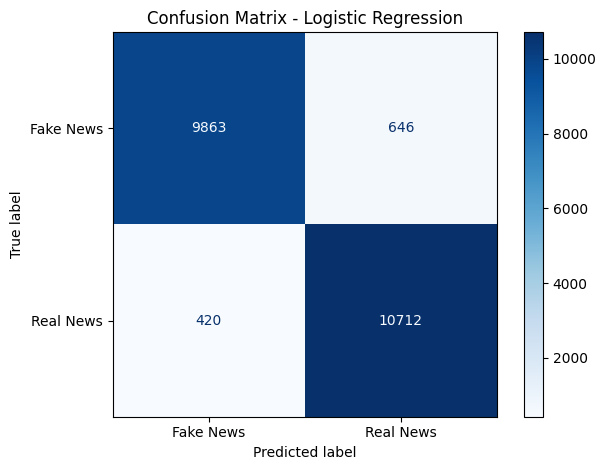


Evaluation: Naive Bayes
Accuracy:       0.8667
Macro Precision:0.8678
Macro Recall:   0.8659
Macro F1:       0.8664

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.88      0.84      0.86     10509
   Real News       0.85      0.89      0.87     11132

    accuracy                           0.87     21641
   macro avg       0.87      0.87      0.87     21641
weighted avg       0.87      0.87      0.87     21641



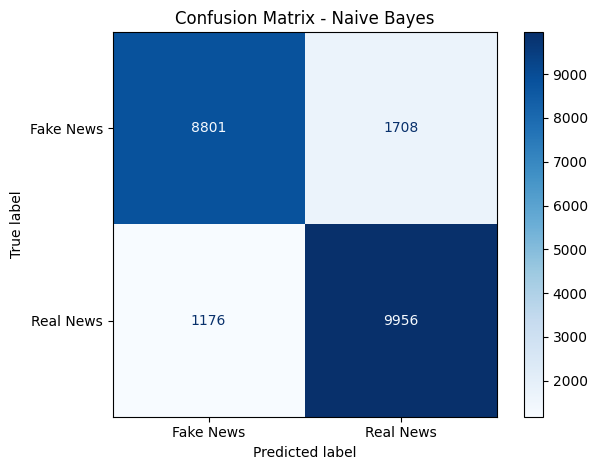


Evaluation: Linear SVM
Accuracy:       0.9636
Macro Precision:0.9639
Macro Recall:   0.9634
Macro F1:       0.9636

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.97      0.95      0.96     10509
   Real News       0.96      0.97      0.96     11132

    accuracy                           0.96     21641
   macro avg       0.96      0.96      0.96     21641
weighted avg       0.96      0.96      0.96     21641



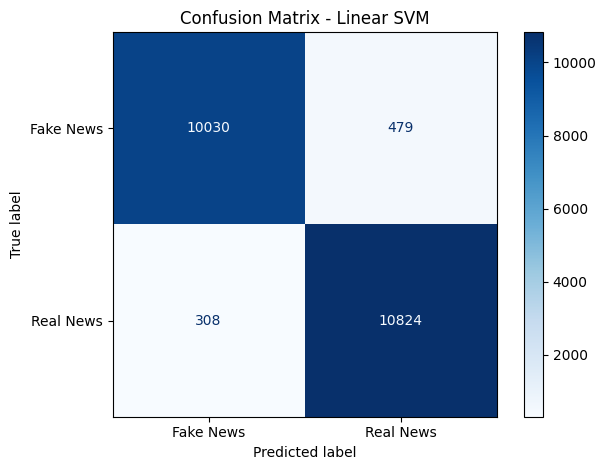


FINAL MODEL COMPARISON


,Model,Accuracy,Precision (Macro),Recall (Macro),Macro F1
0,Linear SVM,0.9636,0.9639,0.9634,0.9636
1,Logistic Regression,0.9507,0.9511,0.9504,0.9507
2,Naive Bayes,0.8667,0.8678,0.8659,0.8664


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


trained_models = {
    "Logistic Regression": lr_pipeline,
    "Naive Bayes": nb_pipeline,
    "Linear SVM": svm_pipeline
}

results = []
predictions = {}

for model_name, trained_model in trained_models.items():


    y_pred, metrics = evaluate_model(
        trained_model,
        X_test,
        y_test,
        model_name
    )

    results.append(metrics)
    predictions[model_name] = y_pred


    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Fake News", "Real News"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))

I used Linear SVM model to predict news labels, identify false positives and false negatives, display a confusion matrix and calculate evaluation metrics.

Using active in-memory trained model (Linear SVM).
Number of test articles: 21641
Predictions completed.

FALSE POSITIVES (Actual: Real, Predicted: Fake)
Count: 308


,Headline,Actual,Predicted
99,Making the Transition Less Chaotic,Real,Fake
108,JIMMY KIMMEL: Republicans ‘Should Be Praying f...,Real,Fake
210,BREAKING: Republican Majority House Caves To O...,Real,Fake
242,YALE Will Tack New Fee Onto Already Outrageous...,Real,Fake
248,LAWLESS: MUSLIM VIOLENCE And Refusal To Assimi...,Real,Fake
256,Here’s How Goldman Sachs Lays People Off | Fin...,Real,Fake
304,THEY LAID THEIR LIVES ON THE LINE FOR US….We G...,Real,Fake
360,Migrant camps in Paris grow as France shuts do...,Real,Fake
626,GAME ON! California State Senator to Enter U.S...,Real,Fake
631,FORD’S NEW CEO SNUBS President Trump…Will Buil...,Real,Fake



FALSE NEGATIVES (Actual: Fake, Predicted: Real)
Count: 479


,Headline,Actual,Predicted
8,What a Sensory Isolation Tank Taught Me About ...,Fake,Real
28,Cuba releases all 53 political prisoners to co...,Fake,Real
59,Weiner Rising in White House: Ally of Disgrace...,Fake,Real
137,"Lady Gaga at the Super Bowl: No Controversy, L...",Fake,Real
141,Sean Spicer: Donald Trump Asked Gen. Flynn to ...,Fake,Real
151,The Trump Recession: He’s linked himself to po...,Fake,Real
194,YouTube Reinstates MILO’s Livestream Morning A...,Fake,Real
199,"Sorry, Hillary, but we’re done: Keep repeating...",Fake,Real
202,Mother Accused of Having Sex with Five Underag...,Fake,Real
265,Swedish Pensioner Prosecuted for ’Hate’ for Ac...,Fake,Real


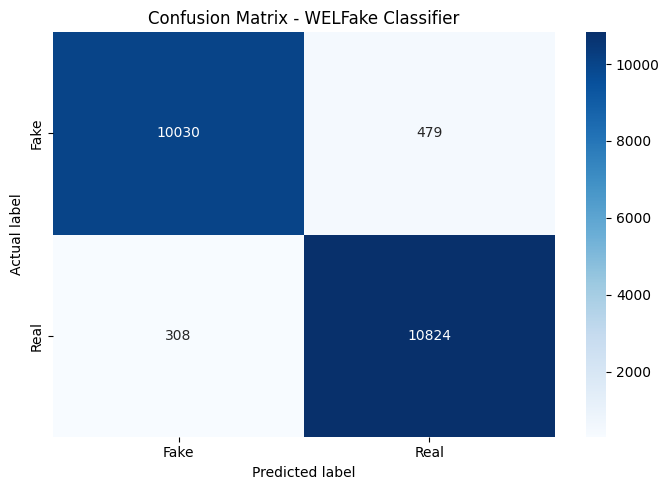


CLASSIFICATION PERFORMANCE
------------------------------------------------------------
Accuracy:  0.9636
Macro Precision: 0.9639
Macro Recall: 0.9634
Macro F1: 0.9636

Detailed classification report:
              precision    recall  f1-score   support

        Fake       0.97      0.95      0.96     10509
        Real       0.96      0.97      0.96     11132

    accuracy                           0.96     21641
   macro avg       0.96      0.96      0.96     21641
weighted avg       0.96      0.96      0.96     21641


Files saved:
1. false_positive_examples.csv
2. false_negative_examples.csv
3. all_test_predictions.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


if "svm_pipeline" in globals():
    model = svm_pipeline




if "model" not in globals():
    raise ValueError("No trained model found in memory. Please run the training cells first.")

print("Using active in-memory trained model (Linear SVM).")




if "X_test" not in globals() or "y_test" not in globals():
    raise ValueError(
        "X_test or y_test is missing. Run the train-test split "
        "and training cells again."
    )




y_pred = model.predict(X_test)

print("Number of test articles:", len(y_test))
print("Predictions completed.")




label_names = {
    0: "Fake",
    1: "Real"
}


if "title" in df.columns and X_test.index.isin(df.index).all():
    headlines = df.loc[X_test.index, "title"].fillna("")
else:
    headlines = pd.Series(
        ["Headline unavailable"] * len(X_test),
        index=X_test.index
    )


article_text = X_test

error_df = pd.DataFrame({
    "Headline": headlines.to_numpy(),
    "Article_Text": article_text.to_numpy(),
    "Actual_Label": np.asarray(y_test),
    "Predicted_Label": np.asarray(y_pred)
})

error_df["Actual"] = error_df["Actual_Label"].map(label_names)
error_df["Predicted"] = error_df["Predicted_Label"].map(label_names)





false_positives = error_df[
    (error_df["Actual_Label"] == 1) &
    (error_df["Predicted_Label"].astype(int) == 0)
].copy()


false_negatives = error_df[
    (error_df["Actual_Label"] == 0) &
    (error_df["Predicted_Label"].astype(int) == 1)
].copy()

print("\n" + "=" * 60)
print("FALSE POSITIVES (Actual: Real, Predicted: Fake)")
print("=" * 60)
print("Count:", len(false_positives))
display(false_positives[["Headline", "Actual", "Predicted"]].head(10))

print("\n" + "=" * 60)
print("FALSE NEGATIVES (Actual: Fake, Predicted: Real)")
print("=" * 60)
print("Count:", len(false_negatives))
display(false_negatives[["Headline", "Actual", "Predicted"]].head(10))




from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix - WELFake Classifier")
plt.tight_layout()
plt.show()




print("\nCLASSIFICATION PERFORMANCE")
print("-" * 60)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro Precision: {precision_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro Recall: {recall_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["Fake", "Real"], zero_division=0))




false_positives.to_csv("false_positive_examples.csv", index=False)
false_negatives.to_csv("false_negative_examples.csv", index=False)
error_df.to_csv("all_test_predictions.csv", index=False)

print("\nFiles saved:")
print("1. false_positive_examples.csv")
print("2. false_negative_examples.csv")
print("3. all_test_predictions.csv")

I displayed the examples of misclassified headlines, for each of the model.

In [ ]:
def show_misclassified_headlines(
    model_name,
    error_results,
    n_examples=10
):
    """
    Display examples of incorrectly classified news headlines.

    Parameters
    ----------
    model_name : str
        Name of the trained model.
    error_results : dict
        Output dictionary generated in Step 6.
    n_examples : int
        Number of examples to display.
    """

    if model_name not in error_results:
        raise ValueError(
            f"No error-analysis results found for {model_name}. "
            "Run Step 6 first."
        )

    misclassified = error_results[model_name]["misclassified"]

    if misclassified.empty:
        print(f"No misclassified headlines found for {model_name}.")
        return misclassified

    columns = [
        "Headline",
        "Actual",
        "Predicted",
        "Article_Text"
    ]

    examples = misclassified[columns].head(n_examples)

    print(f"\nMisclassified headline examples: {model_name}")
    print("-" * 70)

    display(examples)

    return examples

In [ ]:
lr_errors = show_misclassified_headlines(
    model_name="Logistic Regression",
    error_results=error_results,
    n_examples=10
)


nb_errors = show_misclassified_headlines(
    model_name="Naive Bayes",
    error_results=error_results,
    n_examples=10
)


svm_errors = show_misclassified_headlines(
    model_name="Linear SVM",
    error_results=error_results,
    n_examples=10
)


Misclassified headline examples: Logistic Regression
----------------------------------------------------------------------


,Headline,Actual,Predicted,Article_Text
54129,What a Sensory Isolation Tank Taught Me About ...,Fake,Real,"“Take off your clothes, step into the pod and ..."
51887,OBAMA REGIME AGREES TO CUT DEAL WITH IRAN THAT...,Real,Fake,Wouldn t it be great to have a president who m...
56574,‘TOLERANT LEFT’ FIRE-BOMBS Anti-Migration Memb...,Real,Fake,"A high profile, anti-mass migration Member of ..."
6426,Weiner Rising in White House: Ally of Disgrace...,Fake,Real,Jared Kushner and his wife Ivanka Trump enlist...
30981,HOW VOTING FOR TRUMP Will Help America To Expo...,Real,Fake,Even the most hardened Cruz supporters will be...
69529,Mission Accomplished: Consumer Sentiment Plumm...,Fake,Real,Consumer sentiment unexpectedly dropped in Jun...
24153,Making the Transition Less Chaotic,Real,Fake,Making the Transition Less Chaotic November 20...
65100,JIMMY KIMMEL: Republicans ‘Should Be Praying f...,Real,Fake,Late-night TV host Jimmy Kimmel opened his pro...
24685,"Lady Gaga at the Super Bowl: No Controversy, L...",Fake,Real,"Lady Gaga went for one big, glittering, divers..."
34940,The Trump Recession: He’s linked himself to po...,Fake,Real,"Back in March, some of the financial sector’s ..."



Misclassified headline examples: Naive Bayes
----------------------------------------------------------------------


,Headline,Actual,Predicted,Article_Text
54129,What a Sensory Isolation Tank Taught Me About ...,Fake,Real,"“Take off your clothes, step into the pod and ..."
47443,"Massive Anti-Trump Protests, Union Square NYC ...",Real,Fake,17 mins ago 2 Views 0 Comments 0 Likes New Z...
51887,OBAMA REGIME AGREES TO CUT DEAL WITH IRAN THAT...,Real,Fake,Wouldn t it be great to have a president who m...
56574,‘TOLERANT LEFT’ FIRE-BOMBS Anti-Migration Memb...,Real,Fake,"A high profile, anti-mass migration Member of ..."
37759,Unskewing Facebook will take all kinds: Column,Fake,Real,"Shortages of women, minorities and conservativ..."
6426,Weiner Rising in White House: Ally of Disgrace...,Fake,Real,Jared Kushner and his wife Ivanka Trump enlist...
13454,GREAT JOB! WILBUR ROSS Destroys Pro-Paris Acco...,Real,Fake,Commerce Secretary Wilbur Ross is one smart ma...
34352,Can Donald Trump recover from this?,Fake,Real,Donald Trump's October Surprise is so explicit...
22462,The Tyranny of Other People’s Vacation Photos ...,Fake,Real,Chief among my favorite Facebook memories is t...
31913,How 2016 became the fact-check election,Fake,Real,Spin and overstatement have long been a part o...



Misclassified headline examples: Linear SVM
----------------------------------------------------------------------


,Headline,Actual,Predicted,Article_Text
54129,What a Sensory Isolation Tank Taught Me About ...,Fake,Real,"“Take off your clothes, step into the pod and ..."
38704,Cuba releases all 53 political prisoners to co...,Fake,Real,Cuba has completed the release of 53 political...
6426,Weiner Rising in White House: Ally of Disgrace...,Fake,Real,Jared Kushner and his wife Ivanka Trump enlist...
24153,Making the Transition Less Chaotic,Real,Fake,Making the Transition Less Chaotic November 20...
65100,JIMMY KIMMEL: Republicans ‘Should Be Praying f...,Real,Fake,Late-night TV host Jimmy Kimmel opened his pro...
24685,"Lady Gaga at the Super Bowl: No Controversy, L...",Fake,Real,"Lady Gaga went for one big, glittering, divers..."
43940,Sean Spicer: Donald Trump Asked Gen. Flynn to ...,Fake,Real,White House Press Secretary Sean Spicer told r...
34940,The Trump Recession: He’s linked himself to po...,Fake,Real,"Back in March, some of the financial sector’s ..."
71886,YouTube Reinstates MILO’s Livestream Morning A...,Fake,Real,"Yesterday afternoon, MILO’s YouTube channel wa..."
31303,"Sorry, Hillary, but we’re done: Keep repeating...",Fake,Real,If the 2016 presidential campaign were a footb...
